# 07 — Testing, Eight-Experiment Comparison, and Interpretability

This notebook first visualizes **all eight tuned configurations**, using their nested cross-validation estimates from Notebook 06. It then refits **only the preselected winner for each target** on all 240 training students and evaluates each once on the 60 reserved students. The holdout is **not** used to pick the model. Existing exploratory contact with the same dataset is a limitation.

We generate a baseline comparison, confusion matrices, real prediction records, model-complexity evidence and permutation importance. These figures replace illustrative preview PNGs.

In [2]:
from pathlib import Path
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'results' / 'figures'
MODELS = ROOT / 'models'
for p in [TABLES, FIGURES, MODELS, DATA/'processed']:
    p.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def make_preprocessor(X):
    numerical = X.select_dtypes(include='number').columns.tolist()
    categorical = [c for c in X.columns if c not in numerical]
    # Fit is performed inside each CV training fold, never before splitting.
    return ColumnTransformer([
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical),
        ('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ]), numerical)
    ], remainder='drop')


ModuleNotFoundError: No module named 'numpy'

In [2]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score,f1_score,balanced_accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

meta=json.loads((DATA/'processed'/'experiment_config.json').read_text())
chosen=json.loads((MODELS/'demo_model_selection.json').read_text())
df=pd.read_csv(DATA/'processed'/'dataset2_cleaned.csv')
split=pd.read_csv(DATA/'processed'/'split_indices.csv')
tr=split['split'].eq('train').to_numpy(); te=split['split'].eq('test').to_numpy()
all_cv=pd.concat([pd.read_csv(TABLES/'comparison_3class.csv'),pd.read_csv(TABLES/'comparison_5class.csv')],ignore_index=True)

def instantiate(name):
    return {
       'Logistic Regression':LogisticRegression(max_iter=2000,random_state=42),
       'Decision Tree':DecisionTreeClassifier(random_state=42),
       'Random Forest':RandomForestClassifier(random_state=42,n_jobs=1),
       'SVM (RBF)':SVC(), 'KNN':KNeighborsClassifier(),
       'Gradient Boosting':GradientBoostingClassifier(random_state=42)
    }[name]

def y_for(task):
    y=df[meta['target']]
    return y.map({int(k):v for k,v in meta['three_class_mapping'].items()}) if task=='3class' else y

def chart_for(metric,path,label):
    fig,axs=plt.subplots(1,2,figsize=(13,4.5))
    for ax,task in zip(axs,['3class','5class']):
        subset=all_cv[all_cv.target.eq(task)].copy()
        names=[f"{int(x.n_features) if x.n_features else 'baseline'} • {x.model}" for x in subset.itertuples()]
        colors=['#9babb9' if x.role=='baseline' else ('#318a7f' if x.n_features==7 else '#d1a05b') for x in subset.itertuples()]
        ax.barh(names,subset[metric],color=colors)
        ax.set(title=task.replace('class',' classes'),xlabel=label)
        ax.invert_yaxis()
    fig.suptitle('Nested CV comparisons on training set (real Dataset 2)',fontweight='bold')
    fig.tight_layout();fig.savefig(FIGURES/path,dpi=180,bbox_inches='tight');plt.show()


## 1. Compare tuned models without looking at final test labels

,target,n_features,model,role,nested_cv_macro_f1,nested_cv_macro_f1_sd,nested_cv_accuracy,nested_cv_balanced_accuracy,nested_cv_train_accuracy
0,3class,7,Decision Tree,simple,0.313,0.090,0.392,0.327,0.634
1,3class,7,Gradient Boosting,complex,0.270,0.051,0.462,0.328,0.574
2,3class,15,Decision Tree,simple,0.265,0.055,0.383,0.306,0.609
3,3class,15,Gradient Boosting,complex,0.302,0.024,0.425,0.322,0.747
4,3class,0,Dummy (most frequent),baseline,0.223,0.002,0.504,0.333,0.504
5,5class,7,Decision Tree,simple,0.126,0.024,0.229,0.151,0.529
6,5class,7,Gradient Boosting,complex,0.166,0.041,0.279,0.190,0.500
7,5class,15,Decision Tree,simple,0.203,0.053,0.288,0.217,0.606
8,5class,15,Gradient Boosting,complex,0.169,0.040,0.275,0.195,0.651
9,5class,0,Dummy (most frequent),baseline,0.104,0.002,0.350,0.200,0.350


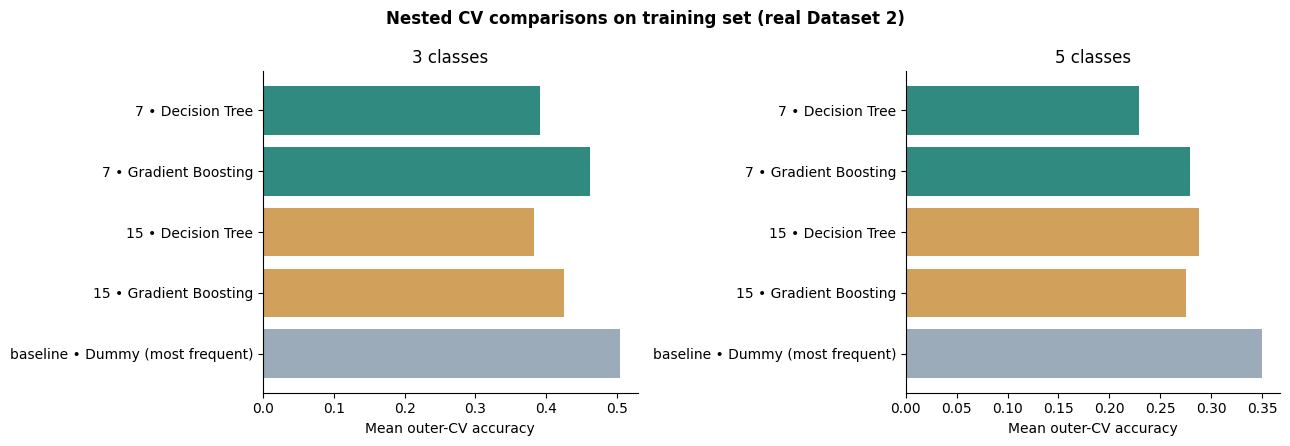

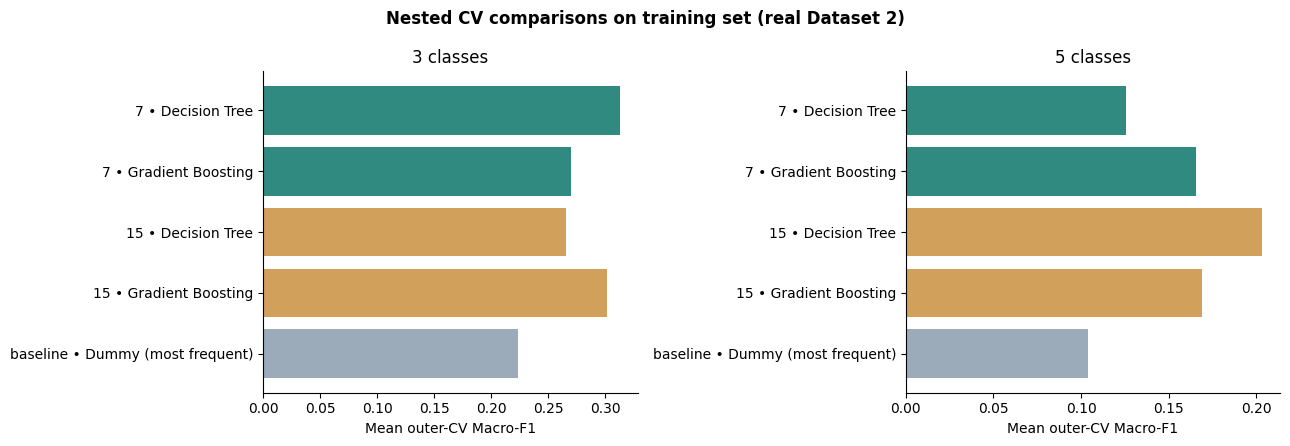

In [3]:
display(all_cv[['target','n_features','model','role','nested_cv_macro_f1','nested_cv_macro_f1_sd','nested_cv_accuracy','nested_cv_balanced_accuracy','nested_cv_train_accuracy']].round(3))
chart_for('nested_cv_accuracy','accuracy_comparison.png','Mean outer-CV accuracy')
chart_for('nested_cv_macro_f1','macro_f1_comparison.png','Mean outer-CV Macro-F1')


## 2. Training vs validation accuracy (nested CV)

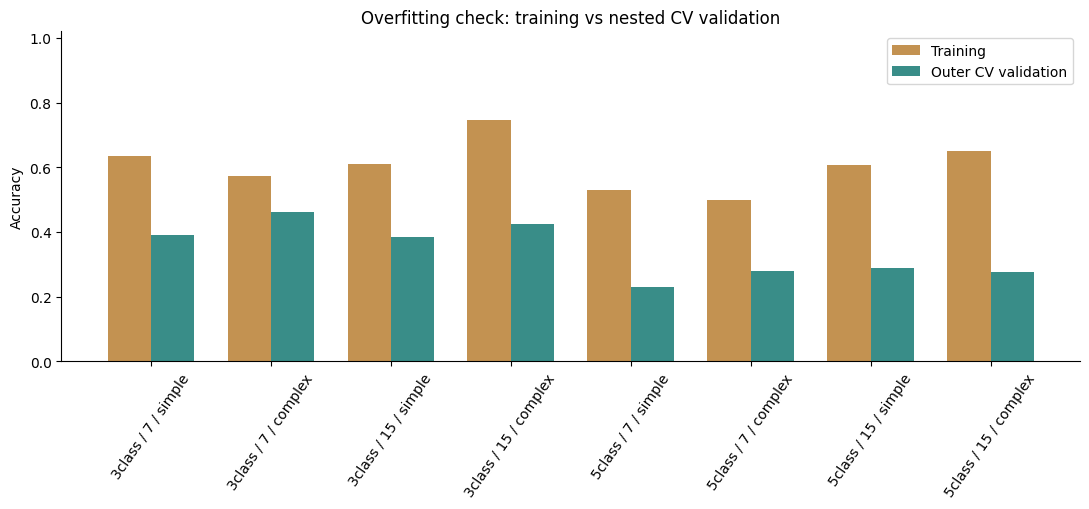

In [4]:
subset=all_cv[~all_cv.role.eq('baseline')].copy()
labels=[f"{x.target} / {x.n_features} / {x.role}" for x in subset.itertuples()]
pos=np.arange(len(labels)); w=.36
fig,ax=plt.subplots(figsize=(11,5.2))
ax.bar(pos-w/2,subset['nested_cv_train_accuracy'],width=w,label='Training',color='#c39251')
ax.bar(pos+w/2,subset['nested_cv_accuracy'],width=w,label='Outer CV validation',color='#398d88')
ax.set(xticks=pos,xticklabels=labels,ylim=(0,1.02),ylabel='Accuracy',title='Overfitting check: training vs nested CV validation')
ax.tick_params(axis='x',rotation=55);ax.legend()
fig.tight_layout();fig.savefig(FIGURES/'training_vs_validation.png',dpi=180,bbox_inches='tight');plt.show()


## 3. Final testing of the two already-selected configurations

We refit each selected pipeline using all **training** students. The 60 held-out records are then predicted once. Test scores are reported against an analogous Dummy baseline, **not** used to pick another model. Keep interpretability discussion tied to the selected model.


3class — Decision Tree, 7 features
              precision    recall  f1-score   support

        High       0.32      0.38      0.34        16
         Low       0.58      0.60      0.59        30
      Medium       0.10      0.07      0.08        14

    accuracy                           0.42        60
   macro avg       0.33      0.35      0.34        60
weighted avg       0.40      0.42      0.41        60



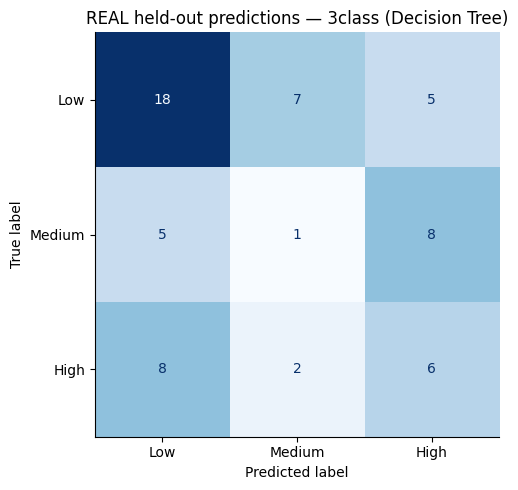


5class — Decision Tree, 15 features
              precision    recall  f1-score   support

           1       0.36      0.43      0.39        21
           2       0.00      0.00      0.00         9
           3       0.11      0.14      0.12        14
           4       0.00      0.00      0.00         8
           5       0.17      0.12      0.14         8

    accuracy                           0.20        60
   macro avg       0.13      0.14      0.13        60
weighted avg       0.17      0.20      0.18        60



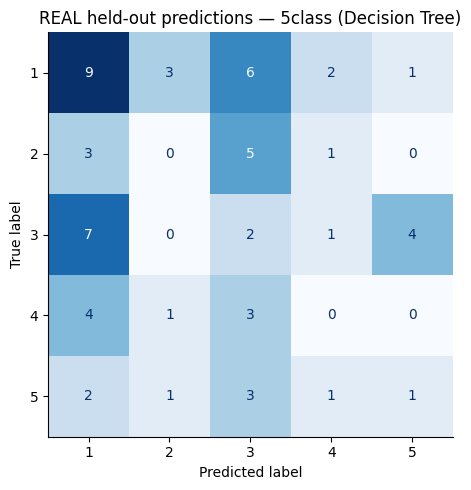

Final heldout performance:


,task,role,model,n_features,test_students,correct_predictions,test_accuracy,test_macro_f1,test_balanced_accuracy
0,3class,selected,Decision Tree,7,60,25,0.417,0.339,0.349
1,3class,dummy_baseline,Dummy (most frequent),0,60,30,0.500,0.222,0.333
2,5class,selected,Decision Tree,15,60,12,0.200,0.131,0.139
3,5class,dummy_baseline,Dummy (most frequent),0,60,21,0.350,0.104,0.200


In [5]:
final_rows=[];prediction_rows=[];fitted={}
for task in ['3class','5class']:
    spec=chosen[task]
    cols=meta['seven_features'] if spec['n_features']==7 else meta['fifteen_features']
    Xtr=df.loc[tr,cols]; Xte=df.loc[te,cols]; yy=y_for(task)
    ytr=yy.loc[tr]; yte=yy.loc[te]
    model=Pipeline([('preprocess',make_preprocessor(Xtr)),('model',instantiate(spec['model']))])
    model.set_params(**spec['best_params'])
    model.fit(Xtr,ytr)
    pred=model.predict(Xte)
    fitted[task]=model
    joblib.dump(model,MODELS/f'best_model_{task}.pkl')
    for role,predictions in [('selected',pred),('dummy_baseline',DummyClassifier(strategy='most_frequent').fit(Xtr,ytr).predict(Xte))]:
        row={'task':task,'role':role,'model':spec['model'] if role=='selected' else 'Dummy (most frequent)',
             'n_features':spec['n_features'] if role=='selected' else 0,
             'test_students':len(yte),
             'correct_predictions':int((predictions==yte).sum()),
             'test_accuracy':accuracy_score(yte,predictions),
             'test_macro_f1':f1_score(yte,predictions,average='macro',zero_division=0),
             'test_balanced_accuracy':balanced_accuracy_score(yte,predictions)}
        final_rows.append(row)
    for rid,actual,predicted in zip(df.index[te],yte,pred):
        prediction_rows.append({'task':task,'row_index':int(rid),'actual':str(actual),'predicted':str(predicted),'correct':bool(actual==predicted)})
    print(f'\n{task} — {spec["model"]}, {spec["n_features"]} features')
    print(classification_report(yte,pred,zero_division=0))
    labs=['Low','Medium','High'] if task=='3class' else [1,2,3,4,5]
    fig,ax=plt.subplots(figsize=(6.2,5))
    ConfusionMatrixDisplay.from_predictions(yte,pred,labels=labs,cmap='Blues',colorbar=False,ax=ax)
    ax.set_title(f'REAL held-out predictions — {task} ({spec["model"]})')
    fig.tight_layout();fig.savefig(FIGURES/f'confusion_matrix_{task}.png',dpi=180,bbox_inches='tight');plt.show()

final=pd.DataFrame(final_rows)
final.to_csv(TABLES/'final_test_results.csv',index=False)
pd.DataFrame(prediction_rows).to_csv(TABLES/'heldout_predictions.csv',index=False)
print('Final heldout performance:');display(final.round(3))


## 4. Permutation feature importance for interpretability

Permutation importance measures how much **Macro-F1 decreases** when one original feature is randomly shuffled. It does **not** reveal causal effects of lifestyle habits, and estimates can be highly variable with 60 test students. It is shown as a descriptive analysis after final model selection; it does not modify the winner.

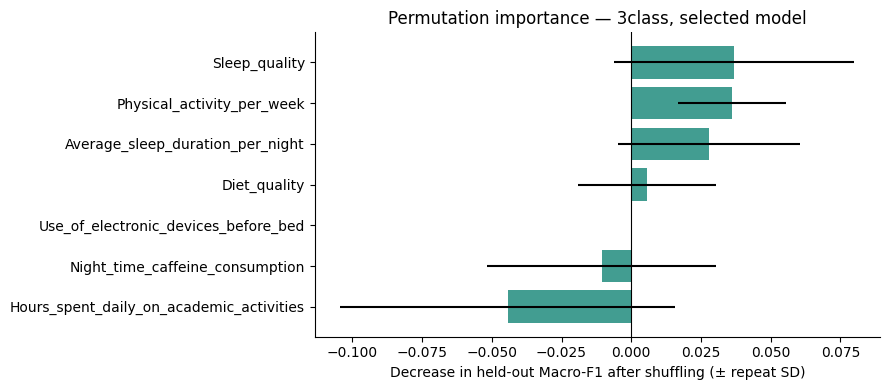

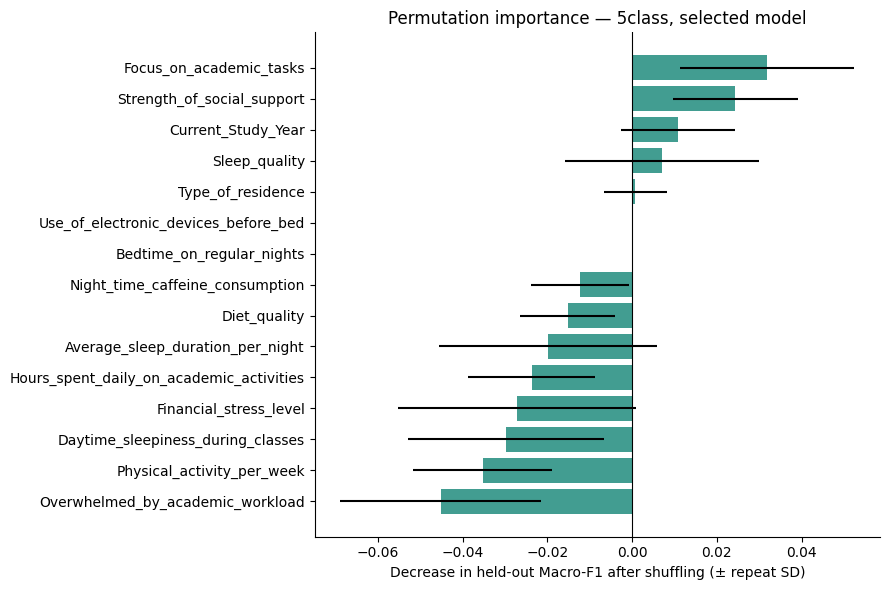

In [6]:
importance_rows=[]
for task in ['3class','5class']:
    spec=chosen[task]
    cols=meta['seven_features'] if spec['n_features']==7 else meta['fifteen_features']
    Xte=df.loc[te,cols];yy=y_for(task).loc[te]
    scores=permutation_importance(fitted[task],Xte,yy,scoring='f1_macro',n_repeats=20,random_state=42,n_jobs=1)
    for i,feature in enumerate(cols):
        importance_rows.append({'task':task,'feature':feature,'importance_mean':scores.importances_mean[i],
           'importance_std':scores.importances_std[i]})
imp=pd.DataFrame(importance_rows)
imp.to_csv(TABLES/'feature_importance.csv',index=False)
for task in ['3class','5class']:
    part=imp[imp.task.eq(task)].sort_values('importance_mean',ascending=True)
    fig,ax=plt.subplots(figsize=(9,max(4,len(part)*.4)))
    ax.barh(part['feature'],part['importance_mean'],xerr=part['importance_std'],color='#429d91')
    ax.axvline(0,color='black',lw=.8)
    ax.set(xlabel='Decrease in held-out Macro-F1 after shuffling (± repeat SD)',
           title=f'Permutation importance — {task}, selected model')
    fig.tight_layout();fig.savefig(FIGURES/f'feature_importance_{task}.png',dpi=180,bbox_inches='tight');plt.show()


## 5. Discussion prompts for final report

- **Performance:** Compare the eight nested CV results **within the same target definition**; state if either approach beats its most-frequent Dummy baseline (especially in Macro-F1).
- **Interpretability:** Discuss permutation importance, noting sampling uncertainty and lack of causal interpretation.
- **Complexity:** Contrast selected algorithm types, measured fit times (`model_complexity.csv`), and 7-versus-15 input burden.
- **Limitations:** Only 300 self-reported cases; inconsistent stress perceptions; class imbalance; proxy-variable concerns (e.g. `Financial_stress_level` and `Overwhelmed_by_academic_workload`); class grouping loses granularity; repeated exploratory use of data and test split limits claims of independence.
- **Existing approaches:** The user will independently compare published papers with this study in the final report. **Do not claim external improvements without matching task, dataset and validation.**
- **Conclusion:** Describe the selected algorithms/feature sets *and actual results*; do not promise useful individual stress diagnosis when validation scores are weak.